In [81]:
import os
from langchain.agents import create_agent
#from langchain_core.tools import tool -? used for @tool
from langchain_core.tools import Tool
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_astradb import AstraDBVectorStore
from langchain_groq import ChatGroq
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END
from langgraph.graph import StateGraph
from typing import Annotated, TypedDict, Sequence
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages

In [ ]:
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

ASTRA_DB_API_ENDPOINT = ""
ASTRA_DB_APPLICATION_TOKEN = ""

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vector_store = AstraDBVectorStore(
    collection_name="agentic_rag",
    embedding=embeddings,
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    namespace=None,
)


model = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=200,
    temperature=0
)

retriver = vector_store.as_retriever()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3038.15it/s]


In [83]:
def retriever_tool_func(query: str) -> str:
    print("📚 Using RAGRetriever tool")
    docs = retriver.invoke(query)
    return "\n".join([doc.page_content for doc in docs])




In [84]:
#Retriver tools for vector database
retriever_tool=Tool(
    name="RAGRetriever",
    description="Use this tool to fetch relevant knowledge base info",
    func=retriever_tool_func
)


In [85]:
import wikipedia

# RAG Tool
retriever_tool = Tool(
    name="RAGRetriever",
    func=retriever_tool_func,
    description=(
        "Search ONLY the internal vector database. "
        "Use this tool when the user requests information "
        "from RAGRetriever, internal documents, or the knowledge base. "
        "Do not use it for questions explicitly assigned to Wikipedia."
    )
)

# Wikipedia Tool
wiki_tool = WikipediaQueryRun(
    api_wrapper=WikipediaAPIWrapper(
        top_k_results=1,
        doc_content_chars_max=500
    ),
    name="WikipediaSearch",
    description=(
        "Search Wikipedia for general encyclopedic information. "
        "Use this tool when the user explicitly requests Wikipedia "
        "or asks for general knowledge from Wikipedia."
    )
)

In [86]:
# ----------------------------
# 2. Define the Agent Node
# ----------------------------



tools = [retriever_tool,wiki_tool]

# Create the agent
agent = create_agent(
   model=model,
   tools=tools

)


In [87]:
# --------------------------
# 3. LangGraph Agent State
# --------------------------

class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

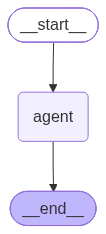

In [88]:
# --------------------------
# 4. Build LangGraph Graph
# --------------------------

builder = StateGraph(AgentState)

builder.add_node("agent", agent)
builder.set_entry_point("agent")
builder.add_edge("agent", END)

graph = builder.compile()
graph

In [94]:
from langchain_core.messages import AIMessage, ToolMessage

if __name__ == "__main__":
    user_query = "What is an agent loop form retriver tool and  then search wikipidea for what is machine learning?"

    state = {"messages": [HumanMessage(content=user_query)]}

    result = graph.invoke(state)

    print("\n========== TOOL EXECUTION HISTORY ==========")

    for msg in result["messages"]:

        if isinstance(msg, AIMessage) and msg.tool_calls:
            for call in msg.tool_calls:
                print(f"🔧 Tool Called: {call['name']}")
                print(f"📥 Input: {call['args']}")

        elif isinstance(msg, ToolMessage):
            print(f"✅ Tool Executed: {msg.name}")
            print(f"📤 Output: {str(msg.content)[:200]}")

    print("\n========== FINAL ANSWER ==========")
    print(result["messages"][-1].content)

📚 Using RAGRetriever tool

========== TOOL EXECUTION HISTORY ==========
🔧 Tool Called: RAGRetriever
📥 Input: {'__arg1': 'What is an agent loop retriever tool?'}
🔧 Tool Called: WikipediaSearch
📥 Input: {'query': 'What is machine learning?'}
✅ Tool Executed: RAGRetriever
📤 Output: Tool use

The agent learns to call external APIs for extra information that is missing from the model weights (often hard to change after pre-training), including current information, code execution c
✅ Tool Executed: WikipediaSearch
📤 Output: Page: Machine learning
Summary: Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and ge

========== FINAL ANSWER ==========
Here's what I found for both of your requests:

## 1. Agent Loop Retriever Tool (from internal knowledge base)

An **agent loop** is a core component of LLM-powered autonomous agent systems. In this pattern, the agent iteratively:

- **Dec